# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load Dataset

In [2]:
from pathlib import Path

In [3]:
DATA_DIR = Path('C:\\Users\\DELL\\Desktop\\Eigenfaces Explorer')

In [4]:
files = sorted(DATA_DIR.glob('*.jpg'), key=lambda file: int(file.stem.split('_')[0]))

In [5]:
print('Folder exists:', DATA_DIR.exists())

Folder exists: True


In [6]:
print('Total images:', len(files))

Total images: 410


In [7]:
print('First 5 files:')

First 5 files:


In [8]:
for file in files[:5]:
    print(file.name)

1_1.jpg
2_1.jpg
3_1.jpg
4_1.jpg
5_1.jpg


# Inspect Dataset

In [9]:
records = []

In [10]:
for file in files:
    with Image.open(file) as image:
        image.load()
        records.append({'Filename': file.name, 'Group': int(file.stem.split('_')[1]), 
                        'Width': image.width, 'Height': image.height, 'Mode': image.mode})

In [11]:
data = pd.DataFrame(records)

In [12]:
display(data.head())

,Filename,Group,Width,Height,Mode
0,1_1.jpg,1,70,80,L
1,2_1.jpg,1,70,80,L
2,3_1.jpg,1,70,80,L
3,4_1.jpg,1,70,80,L
4,5_1.jpg,1,70,80,L


In [13]:
print('Total images:', len(data))

Total images: 410


In [14]:
print('Total groups:', data['Group'].nunique())

Total groups: 41


In [15]:
print('\nImage sizes and color modes:')


Image sizes and color modes:


In [16]:
print(data.groupby(['Width', 'Height', 'Mode']).size())

Width  Height  Mode
70     80      L       400
               RGB      10
dtype: int64


# Image Preprocessing

In [17]:
WIDTH, HEIGHT = (70, 80)

In [18]:
images = []

In [19]:
for file in files:
    with Image.open(file) as image:
        image = image.convert('L')
        image = image.resize((WIDTH, HEIGHT), Image.Resampling.LANCZOS)
        image_array = np.asarray(image, dtype=np.float64) / 255.0
        images.append(image_array)

In [20]:
images = np.stack(images)

In [21]:
X = images.reshape(len(images), -1)

In [22]:
print('Images shape:', images.shape)

Images shape: (410, 80, 70)


In [23]:
print('PCA data shape:', X.shape)

PCA data shape: (410, 5600)


In [24]:
print('Minimum pixel value:', X.min())

Minimum pixel value: 0.0


In [25]:
print('Maximum pixel value:', X.max())

Maximum pixel value: 1.0


In [26]:
print('Missing pixel values:', np.isnan(X).sum())

Missing pixel values: 0


# Display Sample Faces

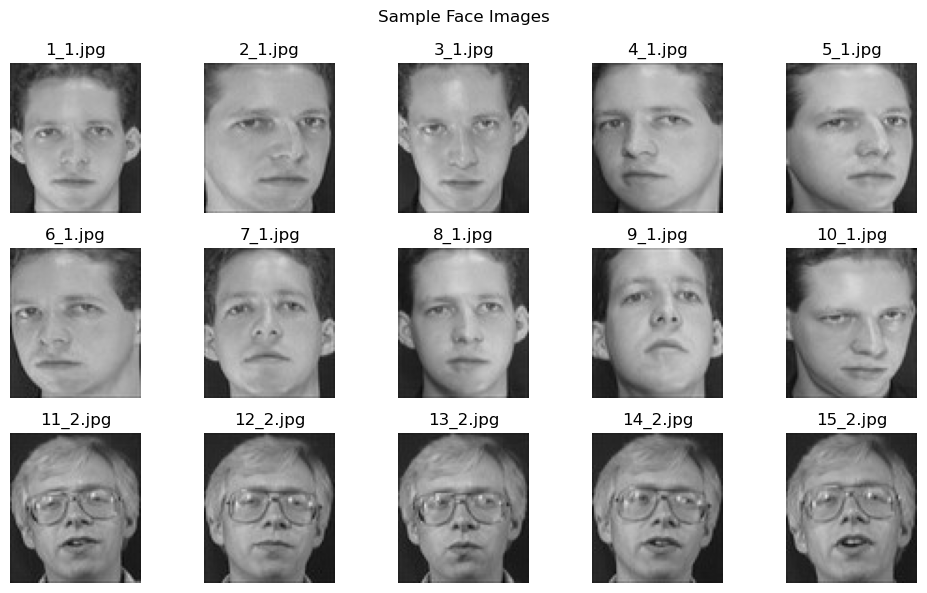

In [27]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))

for ax, i in zip(axes.flat, range(15)):
    ax.imshow(images[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(files[i].name)
    ax.axis('off')

plt.suptitle('Sample Face Images')
plt.tight_layout()
plt.show()

# Train Validation Test Split

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
groups = data['Group'].to_numpy()

In [30]:
indices = np.arange(len(X))

In [31]:
train_idx, remaining_idx = train_test_split(indices, test_size=0.3, random_state=42, stratify=groups)

In [32]:
val_idx, test_idx = train_test_split(remaining_idx, test_size=2 / 3, random_state=42, stratify=groups[remaining_idx])

In [33]:
X_train = X[train_idx]

In [34]:
X_val = X[val_idx]

In [35]:
X_test = X[test_idx]

In [36]:
print('Training shape:', X_train.shape)

Training shape: (287, 5600)


In [37]:
print('Validation shape:', X_val.shape)

Validation shape: (41, 5600)


In [38]:
print('Testing shape:', X_test.shape)

Testing shape: (82, 5600)


# Build and Train PCA Model

In [39]:
from sklearn.decomposition import PCA

In [40]:
max_components = min(X_train.shape[0] - 1, X_train.shape[1])

In [41]:
pca = PCA(n_components=max_components, svd_solver='full')

In [42]:
pca.fit(X_train)

,n_components,286
,copy,True
,whiten,False
,svd_solver,'full'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [43]:
print('PCA model trained successfully!')

PCA model trained successfully!


In [44]:
print('Total components:', pca.n_components_)

Total components: 286


In [45]:
print('Eigenfaces shape:', pca.components_.shape)

Eigenfaces shape: (286, 5600)


# Display Mean Face

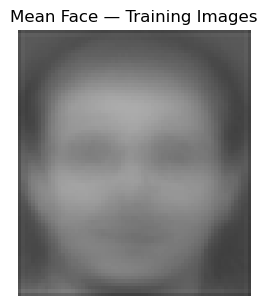

In [46]:
mean_face = pca.mean_.reshape(HEIGHT, WIDTH)

plt.figure(figsize=(3, 4))
plt.imshow(mean_face, cmap='gray', vmin=0, vmax=1)
plt.title('Mean Face — Training Images')
plt.axis('off')
plt.show()

# Display Eigenfaces

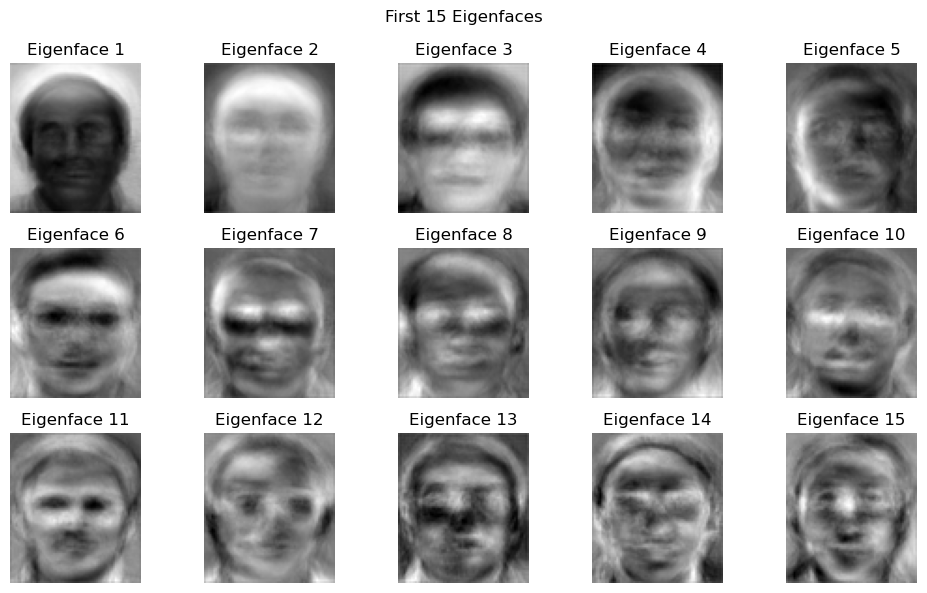

In [48]:
eigenfaces = pca.components_.reshape(pca.n_components_, HEIGHT, WIDTH)

fig, axes = plt.subplots(3, 5, figsize=(10, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces[i], cmap='gray')
    ax.set_title(f'Eigenface {i + 1}')
    ax.axis('off')

plt.suptitle('First 15 Eigenfaces')
plt.tight_layout()
plt.show()

# Explained Variance

In [49]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

In [50]:
k95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)

In [51]:
print('Components for 95% training variance:', k95)

Components for 95% training variance: 120


In [52]:
print('Preserved variance:', round(cumulative_variance[k95 - 1] * 100, 2), '%')

Preserved variance: 95.05 %


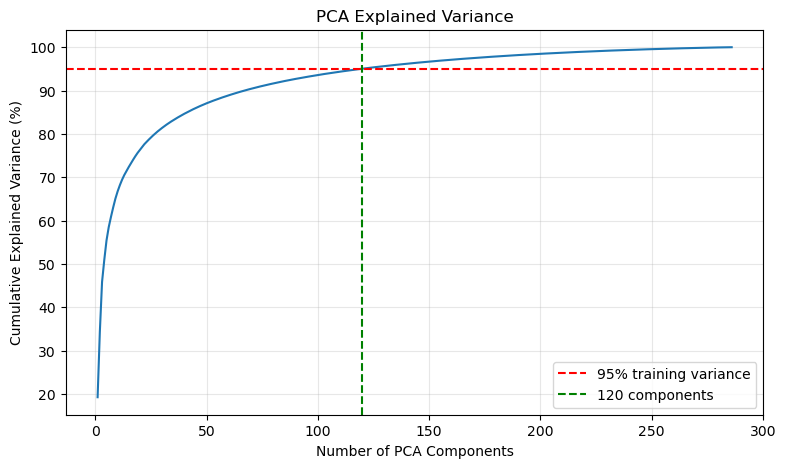

In [53]:
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance * 100)
plt.axhline(95, color='red', linestyle='--', label='95% training variance')
plt.axvline(k95, color='green', linestyle='--', label=f'{k95} components')
plt.xlabel('Number of PCA Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Create Reconstruction Function

In [57]:
def reconstruct(values, k):
    if not 1 <= k <= pca.n_components_:
        raise ValueError(f'k must be between 1 and {pca.n_components_}')
    scores = pca.transform(values)[:, :k]
    reconstructed = scores @ pca.components_[:k] + pca.mean_
    return reconstructed

print('Reconstruction function ready!')

Reconstruction function ready!


# Compare PCA Components

In [58]:
from sklearn.metrics import mean_squared_error

In [59]:
component_options = sorted(set((k for k in [5, 10, 30, 50, 100, 150, k95] if k <= pca.n_components_)))

In [60]:
results = []

In [61]:
for k in component_options:
    reconstructed = reconstruct(X_val, k)
    mse = mean_squared_error(X_val, reconstructed)
    results.append({'Components': k, 'Training Variance (%)': cumulative_variance[k - 1] * 100, 'Validation MSE': mse})

In [62]:
comparison = pd.DataFrame(results)

In [63]:
display(comparison.round(6))

,Components,Training Variance (%),Validation MSE
0,5,55.423679,0.012064
1,10,66.749647,0.009368
2,30,81.397016,0.006376
3,50,87.071863,0.005142
4,100,93.585389,0.004005
5,120,95.047149,0.003789
6,150,96.677526,0.003543


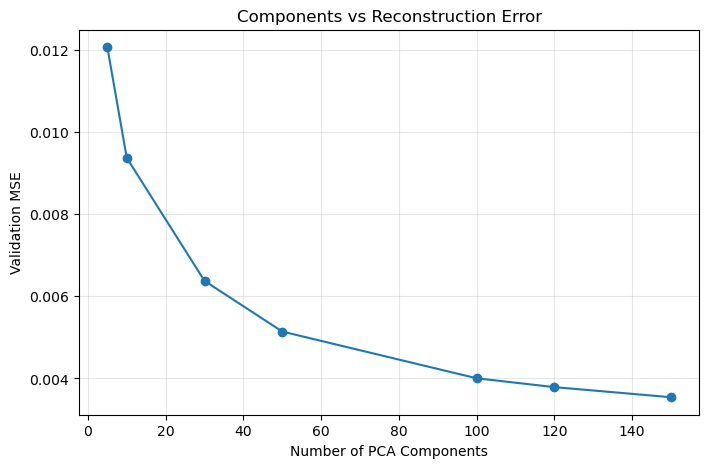

In [64]:
plt.figure(figsize=(8, 5))
plt.plot(comparison['Components'], comparison['Validation MSE'], marker='o')
plt.xlabel('Number of PCA Components')
plt.ylabel('Validation MSE')
plt.title('Components vs Reconstruction Error')
plt.grid(alpha=0.3)
plt.show()

# Check Model Performance

In [65]:
selected_k = k95

In [66]:
test_reconstructed = reconstruct(X_test, selected_k)

In [67]:
test_mse = mean_squared_error(X_test, test_reconstructed)

In [68]:
test_rmse = np.sqrt(test_mse)

In [69]:
test_psnr = 10 * np.log10(1.0 / test_mse) if test_mse > 0 else float('inf')

In [70]:
print('Selected components:', selected_k)

Selected components: 120


In [71]:
print(f'Test MSE:  {test_mse:.6f}')

Test MSE:  0.003811


In [72]:
print(f'Test RMSE: {test_rmse:.6f}')

Test RMSE: 0.061737


In [73]:
print(f'Test PSNR: {test_psnr:.2f} dB')

Test PSNR: 24.19 dB


# Compare Original and Reconstructed Faces

In [74]:
component_counts = sorted(set([10, 50, selected_k]))

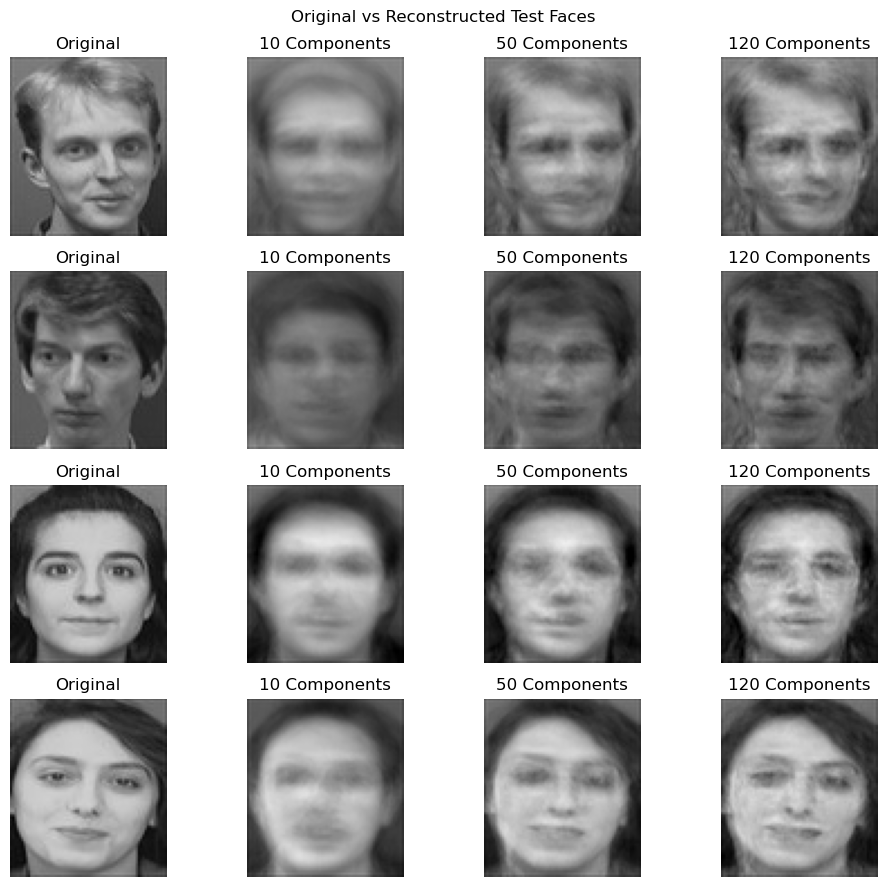

In [78]:
fig, axes = plt.subplots(4, len(component_counts) + 1, figsize=(10, 9))

for row in range(4):
    axes[row, 0].imshow(X_test[row].reshape(HEIGHT, WIDTH), cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title('Original')
    for col, k in enumerate(component_counts, start=1):
        reconstructed = reconstruct(X_test[row:row + 1], k)
        face = reconstructed[0].reshape(HEIGHT, WIDTH)
        axes[row, col].imshow(np.clip(face, 0, 1), cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(f'{k} Components')

for ax in axes.flat:
    ax.axis('off')

plt.suptitle('Original vs Reconstructed Test Faces')
plt.tight_layout()
plt.show()

# Create Face Explorer

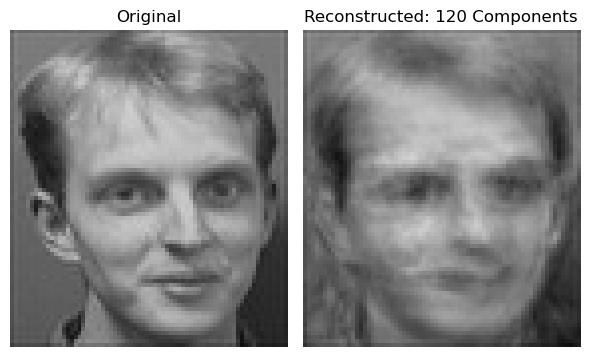

Image: 391_40.jpg
Reconstruction MSE: 0.004729


In [79]:
def explore_face(sample_number=0, k=50):
    if not 0 <= sample_number < len(X_test):
        raise ValueError(f'sample_number must be 0 to {len(X_test) - 1}')
    original = X_test[sample_number:sample_number + 1]
    reconstructed = reconstruct(original, k)
    fig, axes = plt.subplots(1, 2, figsize=(6, 4))
    axes[0].imshow(original[0].reshape(HEIGHT, WIDTH), cmap='gray', vmin=0, vmax=1)
    axes[0].set_title('Original')
    axes[1].imshow(np.clip(reconstructed[0].reshape(HEIGHT, WIDTH), 0, 1), cmap='gray', vmin=0, vmax=1)
    axes[1].set_title(f'Reconstructed: {k} Components')
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Image:', files[test_idx[sample_number]].name)
    print('Reconstruction MSE:', round(mean_squared_error(original, reconstructed), 6))

explore_face(sample_number=0, k=selected_k)

# Try Another Face

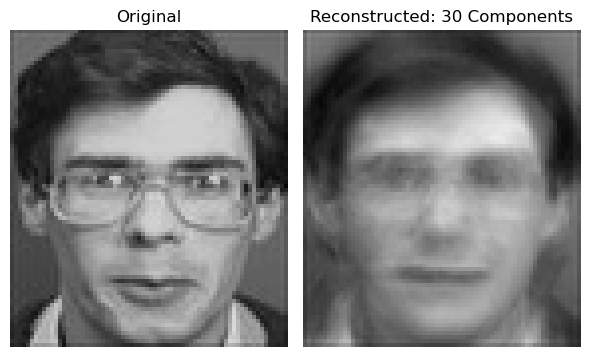

Image: 199_20.jpg
Reconstruction MSE: 0.008155


In [80]:
explore_face(sample_number=5, k=30)

# Save the Model

In [81]:
import joblib

In [82]:
RESULTS_DIR = Path.cwd() / 'eigenfaces_results'

In [83]:
RESULTS_DIR.mkdir(exist_ok=True)

In [84]:
model_bundle = {'pca': pca, 'selected_k': selected_k, 'width': WIDTH, 'height': HEIGHT, 'pixel_scale': 255.0}

In [85]:
model_path = RESULTS_DIR / 'eigenfaces_pca.joblib'

In [86]:
joblib.dump(model_bundle, model_path)

['C:\\Users\\DELL\\Desktop\\Eigenfaces Explorer\\eigenfaces_results\\eigenfaces_pca.joblib']

In [87]:
loaded_bundle = joblib.load(model_path)

In [88]:
print('Model saved and verified!')

Model saved and verified!


In [89]:
print('Location:', model_path)

Location: C:\Users\DELL\Desktop\Eigenfaces Explorer\eigenfaces_results\eigenfaces_pca.joblib
